# Практическая работа 4 (Прошлая работа. Нужна для подготовки 5 практической)

Ниже будет 5 практическая работа

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(
    'titanic.csv',
    encoding='utf-8'
)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
y = df['Survived']
y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


In [ ]:
X = df[['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']]
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,male,7.2500,1,0
1,1,38.0,female,71.2833,1,0
2,3,26.0,female,7.9250,0,0
3,1,35.0,female,53.1000,1,0
4,3,35.0,male,8.0500,0,0


In [ ]:
X.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0


In [ ]:
median_age = df['Age'].median()
median_age

28.0

In [ ]:
X['Age'] = X['Age'].fillna(median_age)

/tmp/ipykernel_3107/3511689133.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Age'] = X['Age'].fillna(median_age)


In [ ]:
X.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0


In [ ]:
X['Sex'] = X['Sex'].map({
    'male': 0,
    'female': 1
})

X.head()

/tmp/ipykernel_3107/2531338254.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Sex'] = X['Sex'].map({


,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,0,7.2500,1,0
1,1,38.0,1,71.2833,1,0
2,3,26.0,1,7.9250,0,0
3,1,35.0,1,53.1000,1,0
4,3,35.0,0,8.0500,0,0


In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Pclass  891 non-null    int64  
 1   Age     891 non-null    float64
 2   Sex     891 non-null    int64  
 3   Fare    891 non-null    float64
 4   SibSp   891 non-null    int64  
 5   Parch   891 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 41.9 KB


In [ ]:
X.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 6)
X_test: (179, 6)
y_train: (712,)
y_test: (179,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled.shape

(712, 6)

In [ ]:
X_test_scaled.shape

(179, 6)

# Практическая работа 5

In [32]:
merged = X.copy()
merged['Survived'] = y.copy()

merged.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0


In [38]:
merged.columns.tolist()

['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

In [36]:
merged.dtypes

,0
Pclass,int64
Age,float64
Sex,int64
Fare,float64
SibSp,int64
Parch,int64
Survived,int64


In [31]:
merged.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


In [40]:
merged.corr().round(2)

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.13,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,-0.08,0.10,-0.23,-0.17,-0.06
Sex,-0.13,-0.08,1.00,0.18,0.11,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.11,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.25,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.54,0.26,-0.04,0.08,1.00


4.	Определите признак с наиболее сильной положительной корреляцией с Survived

Sex и частично Fare

5.	Определите признак с наиболее сильной отрицательной корреляцией с Survived

Pclass

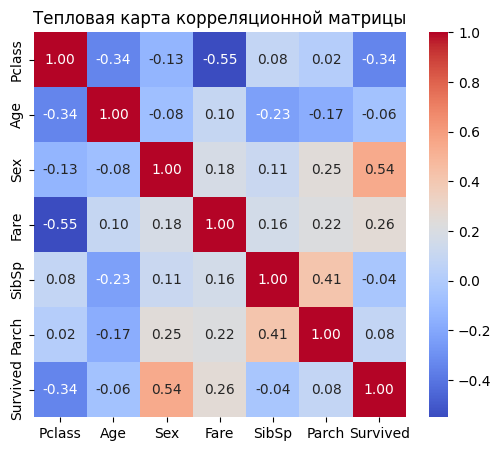

In [59]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(merged.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Тепловая карта корреляционной матрицы')
plt.show()

Какие признаки, по вашему мнению, могут быть наиболее полезны для предсказания Survived?

Я предполагаю, что Sex, Fare и возможно Pclass. Но в Pclass, я не уверен, просто предполагаю, что даже отрицательная корреляция может подсказать целевую перменную

Можно ли выбирать признаки для модели машинного обучения только на основании корреляции?

Думаю, что да